# Задание 4: числовые embeddings — отдельный эксперимент

Исходный `task4.ipynb` сохранён без изменений. Здесь проверяем одну сеть с нелинейным кодированием
каждого числового признака: piecewise linear encoding (PLE), периодические sin/cos признаки и RBF.
Затем признаки совместно обрабатываются MLP. Это не ансамбль. Все операции модели — PyTorch.

Идея numerical embeddings: [Gorishniy et al., 2022](https://arxiv.org/abs/2203.05556).
Реализация ниже самостоятельная; готовые веса и внешние данные не используются.

Протокол общий с другими агентами: исходные train9800/validation2100 (seed42), 2 дополнительных
разбиения development11900 (seed17,83) для лидеров. Audit2100 не используется при поиске.
Многократная валидация сама по себе даёт смещение выбора; подтверждение снижает этот риск, но не устраняет его.
Оптимизируем MSE. Public score исходного решения, сообщённый пользователем:85.55280;
по масштабу предполагается MSE (порядок моделей одинаков для MSE и RMSE).

In [1]:
import base64
import copy
import hashlib
import io
import math
import random
import time
import unittest
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import HTML, Markdown, display
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer, RobustScaler, StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
SELECTION_METRIC = "rmse"  # "rmse", "mse" или "mae"; см. пояснение выше.
assert SELECTION_METRIC in {"rmse", "mse", "mae"}
MAX_EPOCHS = 160
PATIENCE = 25
BATCH_SIZE = 256
# CPU выбран для воспроизводимого сравнения двух реализаций оптимизатора.
# Для большого запуска можно указать "cuda" или "mps", если устройство доступно.
DEVICE = torch.device("cpu")
torch.set_num_threads(2)


def seed_everything(seed=SEED):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True)


seed_everything()
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.25})
print(f"torch={torch.__version__}; numpy={np.__version__}; "
      f"pandas={pd.__version__}; sklearn={sklearn.__version__}; device={DEVICE}")

torch=2.14.1; numpy=2.4.6; pandas=3.0.3; sklearn=1.9.0; device=cpu


In [2]:
candidates = [Path("task4_data"), Path("homeworks/task4_data")]
DATA_DIR = next((p for p in candidates if (p / "train_x.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Запустите ноутбук из корня репозитория или из homeworks.")

train_x = pd.read_csv(DATA_DIR / "train_x.csv", index_col=0)
train_y = pd.read_csv(DATA_DIR / "train_y.csv", index_col=0)
test_table = pd.read_csv(DATA_DIR / "test_x.csv")
assert train_x.index.is_unique and train_y.index.is_unique
assert set(train_x.index) == set(train_y.index), "Индексы признаков и меток не совпадают"
train_y = train_y.loc[train_x.index]
assert list(train_y.columns) == ["year"]
assert "id" in test_table and test_table["id"].is_unique
assert not test_table["id"].isna().any()

feature_columns = list(train_x.columns)
assert len(feature_columns) == 90
assert set(test_table.columns) == set(feature_columns) | {"id"}
test_ids = test_table["id"].copy()
test_x = test_table.loc[:, feature_columns].copy()
assert all(pd.api.types.is_numeric_dtype(t) for t in train_x.dtypes)
assert all(pd.api.types.is_numeric_dtype(t) for t in test_x.dtypes)
X = train_x.to_numpy(dtype=np.float64)
X_test = test_x.to_numpy(dtype=np.float64)
y = torch.tensor(train_y["year"].to_numpy(dtype=np.float32))
assert torch.isfinite(y).all() and len(y) == len(X)
assert torch.equal(y, y.round()), "Годы должны быть целыми"
assert not np.isinf(X).any() and not np.isinf(X_test).any()

print(f"Обучение: {X.shape}; тест: {X_test.shape}; целевая переменная: year")
print(f"Пропуски: train={np.isnan(X).sum()}, test={np.isnan(X_test).sum()}")
print(f"Точные дубликаты train: {train_x.duplicated().sum()}")
for name in ("train_x.csv", "train_y.csv", "test_x.csv"):
    print(name, "SHA256:", hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest())

Обучение: (14000, 90); тест: (6000, 90); целевая переменная: year
Пропуски: train=0, test=0
Точные дубликаты train: 0
train_x.csv SHA256: aab2f64a4fdb0fd6af98ed95fedc9a3d9a54506b1f607da725926f654f5bff89
train_y.csv SHA256: 1f72519091e6e08948c430a1db9b181df28095e0cc9f29694570b40daed683bf
test_x.csv SHA256: 54f91d13c6f61fd634bae76bdad109471585a4ce0b308159be16f768134b4046


train=9800, validation=2100, audit=2100
Train: mean=1998.37, std=11.07, min=1922, max=2011


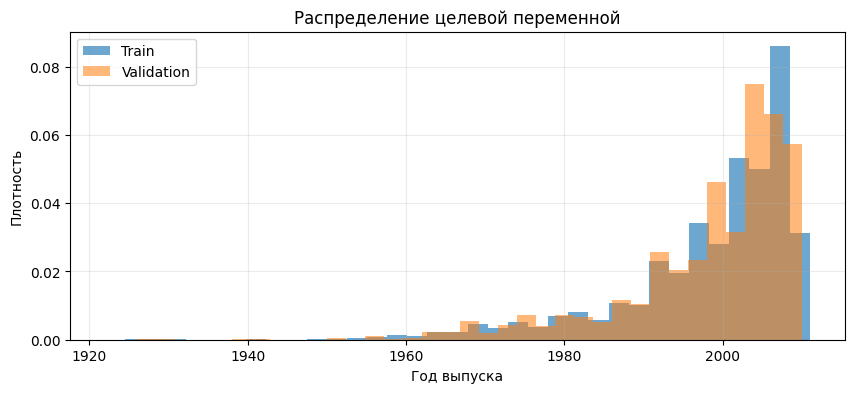

In [3]:
# NumPy/sklearn здесь применяются только к предварительному разбиению данных.
periods = np.digitize(y.tolist(), bins=[1970, 1980, 1990, 2000, 2005])
indices = np.arange(len(X))
development_idx, audit_idx = train_test_split(
    indices, test_size=0.15, random_state=SEED, stratify=periods
)
train_idx, valid_idx = train_test_split(
    development_idx, test_size=0.15 / 0.85, random_state=SEED,
    stratify=periods[development_idx]
)
assert not (set(train_idx) & set(valid_idx) or set(train_idx) & set(audit_idx)
            or set(valid_idx) & set(audit_idx))
assert len(set(train_idx) | set(valid_idx) | set(audit_idx)) == len(X)
row_hashes = pd.util.hash_pandas_object(train_x, index=False)
assert not (set(row_hashes.iloc[train_idx]) & set(row_hashes.iloc[valid_idx]))
assert not (set(row_hashes.iloc[development_idx]) & set(row_hashes.iloc[audit_idx]))
y_train, y_valid = y[train_idx], y[valid_idx]
print(f"train={len(train_idx)}, validation={len(valid_idx)}, audit={len(audit_idx)}")
print(f"Train: mean={y_train.mean():.2f}, std={y_train.std():.2f}, "
      f"min={y_train.min():.0f}, max={y_train.max():.0f}")
fig, ax = plt.subplots()
ax.hist(y_train.tolist(), bins=35, density=True, alpha=0.65, label="Train")
ax.hist(y_valid.tolist(), bins=35, density=True, alpha=0.55, label="Validation")
ax.set(xlabel="Год выпуска", ylabel="Плотность", title="Распределение целевой переменной")
ax.legend()
plt.show()

In [4]:
class FeaturePreprocessor:
    def __init__(self, kind="standard"):
        if kind not in {"standard", "asinh", "quantile"}:
            raise ValueError(kind)
        self.kind = kind
        self.imputer = SimpleImputer(strategy="median", keep_empty_features=True)

    def fit(self, x):
        z = self.imputer.fit_transform(x)
        if self.kind == "asinh":
            self.robust = RobustScaler().fit(z)
            z = np.arcsinh(self.robust.transform(z))
        self.scaler = (
            QuantileTransformer(n_quantiles=min(256, len(z)), output_distribution="normal",
                                subsample=None, random_state=SEED)
            if self.kind == "quantile" else StandardScaler()
        )
        self.scaler.fit(z)
        return self

    def transform(self, x):
        z = self.imputer.transform(x)
        if self.kind == "asinh":
            z = np.arcsinh(self.robust.transform(z))
        z = self.scaler.transform(z).astype(np.float32)
        if not np.isfinite(z).all():
            raise ValueError("Нефинитные признаки после преобразования")
        return torch.from_numpy(z.copy())


class TargetScaler:
    def __init__(self, target):
        self.mean = float(target.mean())
        self.std = max(float(target.std(unbiased=False)), 1e-6)

    def encode(self, target):
        return (target - self.mean) / self.std

    def decode(self, prediction):
        return prediction * self.std + self.mean


@torch.inference_mode()
def regression_metrics(prediction, target):
    assert prediction.shape == target.shape
    error = prediction.double() - target.double()
    mse = error.square().mean().item()
    return {"rmse": math.sqrt(mse), "mse": mse, "mae": error.abs().mean().item()}


def print_metrics(label, values):
    print(f"{label}: RMSE={values['rmse']:.4f}; MSE={values['mse']:.4f}; MAE={values['mae']:.4f}")


constant = y_train.median() if SELECTION_METRIC == "mae" else y_train.mean()
constant_valid = regression_metrics(torch.full_like(y_valid, float(constant)), y_valid)
print_metrics("Константа, validation", constant_valid)

Константа, validation: RMSE=10.9058; MSE=118.9360; MAE=8.1448


In [5]:
class CustomAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
        super().__init__(params, defaults)
        for group in self.param_groups:
            if not math.isfinite(group["lr"]) or group["lr"] < 0:
                raise ValueError("lr должен быть конечным и неотрицательным")
            if not math.isfinite(group["eps"]) or group["eps"] <= 0:
                raise ValueError("eps должен быть конечным и положительным")
            if not math.isfinite(group["weight_decay"]) or group["weight_decay"] < 0:
                raise ValueError("weight_decay должен быть конечным и неотрицательным")
            if len(group["betas"]) != 2 or not all(0 <= b < 1 for b in group["betas"]):
                raise ValueError("betas должны лежать в [0, 1)")

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            beta1, beta2 = group["betas"]
            for parameter in group["params"]:
                grad = parameter.grad
                if grad is None:
                    continue
                if grad.is_sparse or torch.is_complex(parameter):
                    raise RuntimeError("Поддерживаются только плотные вещественные градиенты")
                state = self.state[parameter]
                if not state:
                    state["step"] = 0
                    state["exp_avg"] = torch.zeros_like(parameter)
                    state["exp_avg_sq"] = torch.zeros_like(parameter)
                state["step"] += 1
                m, v = state["exp_avg"], state["exp_avg_sq"]
                m.lerp_(grad, 1 - beta1)
                v.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
                correction1 = 1 - beta1 ** state["step"]
                correction2 = 1 - beta2 ** state["step"]
                denominator = v.sqrt().div_(math.sqrt(correction2)).add_(group["eps"])
                parameter.mul_(1 - group["lr"] * group["weight_decay"])
                parameter.addcdiv_(m, denominator, value=-group["lr"] / correction1)
        return loss

In [6]:
class TestCustomAdamW(unittest.TestCase):
    def test_reference_steps_and_parameter_groups(self):
        generator = torch.Generator().manual_seed(101)
        ours = [nn.Parameter(torch.randn(3, 4, generator=generator, dtype=torch.float64)),
                nn.Parameter(torch.randn(4, generator=generator, dtype=torch.float64))]
        reference = [nn.Parameter(p.detach().clone()) for p in ours]
        def groups(parameters):
            return [{"params": [parameters[0]], "lr": 0.003, "weight_decay": 0.1},
                    {"params": [parameters[1]], "lr": 0.002, "weight_decay": 0.0}]
        custom = CustomAdamW(groups(ours), betas=(0.8, 0.95), eps=1e-6)
        builtin = torch.optim.AdamW(groups(reference), betas=(0.8, 0.95), eps=1e-6,
                                    foreach=False, fused=False)
        for step in range(20):
            for i, (p, q) in enumerate(zip(ours, reference)):
                grad = torch.randn(p.shape, generator=generator, dtype=p.dtype)
                if step % 4 == 0 and i == 1:
                    p.grad = q.grad = None
                else:
                    p.grad = torch.zeros_like(grad) if step == 7 else grad
                    q.grad = p.grad.clone()
            custom.step()
            builtin.step()
            for p, q in zip(ours, reference):
                torch.testing.assert_close(p, q, rtol=1e-11, atol=1e-12)

    def test_none_vs_zero_gradient(self):
        p = nn.Parameter(torch.tensor([2.0], dtype=torch.float64))
        optimizer = CustomAdamW([p], lr=0.1, weight_decay=0.2)
        optimizer.step()
        self.assertEqual(p.item(), 2.0)
        self.assertNotIn(p, optimizer.state)
        p.grad = torch.zeros_like(p)
        optimizer.step()
        self.assertAlmostEqual(p.item(), 1.96)
        self.assertEqual(optimizer.state[p]["step"], 1)

    def test_restore_state(self):
        p = nn.Parameter(torch.tensor([1.0, -2.0], dtype=torch.float64))
        a = CustomAdamW([p])
        p.grad = torch.tensor([0.3, -0.1], dtype=p.dtype)
        a.step()
        q = nn.Parameter(p.detach().clone())
        b = CustomAdamW([q])
        b.load_state_dict(copy.deepcopy(a.state_dict()))
        for _ in range(5):
            p.grad = torch.tensor([-0.2, 0.4], dtype=p.dtype)
            q.grad = p.grad.clone()
            a.step()
            b.step()
        torch.testing.assert_close(p, q, rtol=0, atol=0)

    def test_invalid_settings(self):
        for kwargs in [{"lr": -1}, {"eps": 0}, {"betas": (1, 0.9)}, {"weight_decay": -1}]:
            with self.assertRaises(ValueError):
                CustomAdamW([nn.Parameter(torch.ones(1))], **kwargs)


suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestCustomAdamW)
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful()

test_invalid_settings (__main__.TestCustomAdamW.test_invalid_settings) ... ok
test_none_vs_zero_gradient (__main__.TestCustomAdamW.test_none_vs_zero_gradient) ... ok
test_reference_steps_and_parameter_groups (__main__.TestCustomAdamW.test_reference_steps_and_parameter_groups) ... ok
test_restore_state (__main__.TestCustomAdamW.test_restore_state) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.016s

OK


In [7]:
class ResidualBlock(nn.Module):
    def __init__(self, width, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(width), nn.Linear(width, width * 2), nn.SiLU(),
            nn.Dropout(dropout), nn.Linear(width * 2, width), nn.Dropout(dropout)
        )
        nn.init.zeros_(self.net[-2].weight)
        nn.init.zeros_(self.net[-2].bias)

    def forward(self, x):
        return x + self.net(x)


class YearRegressor(nn.Module):
    def __init__(self, n_features, architecture="residual", width=128, dropout=0.15):
        super().__init__()
        if architecture == "linear":
            self.net = nn.Linear(n_features, 1)
        elif architecture == "mlp":
            self.net = nn.Sequential(
                nn.Linear(n_features, width), nn.ReLU(), nn.Dropout(dropout),
                nn.Linear(width, width), nn.ReLU(), nn.Dropout(dropout), nn.Linear(width, 1)
            )
        elif architecture == "residual":
            self.net = nn.Sequential(
                nn.Linear(n_features, width), nn.SiLU(),
                ResidualBlock(width, dropout), ResidualBlock(width, dropout),
                nn.LayerNorm(width), nn.SiLU(), nn.Linear(width, 1)
            )
        else:
            raise ValueError(architecture)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def build_optimizer(model, kind, lr, weight_decay):
    decay, no_decay = [], []
    for parameter in model.parameters():
        (decay if parameter.ndim >= 2 else no_decay).append(parameter)
    groups = [{"params": decay, "weight_decay": weight_decay},
              {"params": no_decay, "weight_decay": 0.0}]
    if kind == "custom":
        return CustomAdamW(groups, lr=lr)
    if kind == "builtin":
        return torch.optim.AdamW(groups, lr=lr, foreach=False, fused=False)
    raise ValueError(kind)


@torch.inference_mode()
def predict(model, features, target_scaler, batch_size=1024):
    model.eval()
    outputs = [model(batch.to(DEVICE)).cpu() for batch in features.split(batch_size)]
    return target_scaler.decode(torch.cat(outputs))


def make_loader(features, targets, seed):
    return DataLoader(TensorDataset(features, targets), batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(seed), num_workers=0)


def train_epoch(model, loader, optimizer):
    model.train()
    loss_fn = nn.L1Loss() if SELECTION_METRIC == "mae" else nn.MSELoss()
    total_loss, total_grad, count = 0.0, 0.0, 0
    for features, targets in loader:
        features, targets = features.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        prediction = model(features)
        assert prediction.shape == targets.shape
        loss = loss_fn(prediction, targets)
        if not torch.isfinite(loss):
            raise RuntimeError("Обучение разошлось")
        loss.backward()
        grad_norm = nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0,
                                           error_if_nonfinite=True)
        optimizer.step()
        total_loss += loss.item() * len(features)
        total_grad += float(grad_norm) * len(features)
        count += len(features)
    return total_loss / count, total_grad / count


def learning_rate(config, epoch):
    # Та же функция используется при final refit, без изменения горизонта.
    phase = (epoch - 1) / max(1, MAX_EPOCHS - 1)
    return config["lr"] * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * phase)))


def fit_experiment(config, optimizer_kind="builtin", seed=SEED):
    seed_everything(seed)
    preprocess = FeaturePreprocessor(config["preprocessing"]).fit(X[train_idx])
    xt, xv = preprocess.transform(X[train_idx]), preprocess.transform(X[valid_idx])
    target_scaler = TargetScaler(y_train)
    loader = make_loader(xt, target_scaler.encode(y_train), seed)
    model = YearRegressor(xt.shape[1], config["architecture"], config["width"],
                          config["dropout"]).to(DEVICE)
    optimizer = build_optimizer(model, optimizer_kind, config["lr"], config["weight_decay"])
    best_score, best_epoch, best_state, stale = math.inf, 0, None, 0
    history = []
    started = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        lr = learning_rate(config, epoch)
        for group in optimizer.param_groups:
            group["lr"] = lr
        loss, grad_norm = train_epoch(model, loader, optimizer)
        train_metrics = regression_metrics(predict(model, xt, target_scaler), y_train)
        valid_metrics = regression_metrics(predict(model, xv, target_scaler), y_valid)
        score = valid_metrics[SELECTION_METRIC]
        history.append({"epoch": epoch, "loss": loss, "grad_norm": grad_norm, "lr": lr,
                        **{f"train_{k}": v for k, v in train_metrics.items()},
                        **{f"valid_{k}": v for k, v in valid_metrics.items()}})
        if score < best_score:
            best_score, best_epoch, stale = score, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
        if epoch == 1 or epoch % 20 == 0:
            print(f"{config['name']} / {optimizer_kind}: epoch={epoch:3d}, "
                  f"train RMSE={train_metrics['rmse']:.4f}, valid RMSE={valid_metrics['rmse']:.4f}",
                  flush=True)
        if stale >= PATIENCE:
            break
    assert best_state is not None
    model.load_state_dict(best_state)
    predictions = predict(model, xv, target_scaler)
    result = dict(config=dict(config), optimizer=optimizer_kind, model=model.cpu(),
                  preprocessing=preprocess, target_scaler=target_scaler, history=history,
                  best_epoch=best_epoch, metrics=regression_metrics(predictions, y_valid),
                  valid_prediction=predictions, seconds=time.perf_counter() - started)
    print_metrics(f"Лучший checkpoint ({best_epoch} эпоха)", result["metrics"])
    return result

In [8]:
import json
import statistics

ARTIFACT_DIR = Path("/tmp/task4_embeddings")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
SUBMISSION_DIR = DATA_DIR / "Submission"
SUBMISSION_DIR.mkdir(exist_ok=True)


def split_for_seed(seed):
    if seed == 42:
        return train_idx.copy(), valid_idx.copy()
    return train_test_split(development_idx, test_size=2100 / len(development_idx),
                            random_state=seed, stratify=periods[development_idx])


class NumericalEmbedding(nn.Module):
    def __init__(self, training_features, kind, bins=8, scale=0.1):
        super().__init__()
        self.kind, self.bins = kind, bins
        d = training_features.shape[1]
        if kind in {"ple", "rbf"}:
            quantiles = torch.linspace(0, 1, bins + 1)
            edges = torch.quantile(training_features, quantiles, dim=0).T.contiguous()
            self.register_buffer("left", edges[:, :-1])
            self.register_buffer("width", (edges[:, 1:] - edges[:, :-1]).clamp_min(1e-4))
        elif kind == "periodic":
            self.frequency = nn.Parameter(torch.randn(d, bins) * scale)
        self.output_size = d if kind == "none" else d * (1 + bins * (2 if kind == "periodic" else 1))

    def forward(self, x):
        if self.kind == "none":
            return x
        if self.kind == "ple":
            z = ((x.unsqueeze(-1) - self.left) / self.width).clamp(0, 1)
        elif self.kind == "rbf":
            z = torch.exp(-0.5 * ((x.unsqueeze(-1) - (self.left + self.width / 2)) /
                                 self.width.clamp_min(0.2)).square())
        elif self.kind == "periodic":
            phase = 2 * math.pi * x.unsqueeze(-1) * self.frequency
            z = torch.cat([phase.sin(), phase.cos()], dim=-1)
        else:
            raise ValueError(self.kind)
        return torch.cat([x.clamp(-5, 5), z.flatten(1)], dim=1)


class EmbeddedRegressor(nn.Module):
    def __init__(self, training_features, config):
        super().__init__()
        self.embedding = NumericalEmbedding(training_features, config["embedding"],
                                            config["bins"], config["scale"])
        layers, previous = [], self.embedding.output_size
        for _ in range(config["depth"]):
            layers.append(nn.Linear(previous, config["width"]))
            if config["norm"] == "bn":
                layers.append(nn.BatchNorm1d(config["width"]))
            elif config["norm"] == "ln":
                layers.append(nn.LayerNorm(config["width"]))
            layers.extend([nn.SiLU(), nn.Dropout(config["dropout"])])
            previous = config["width"]
        layers.append(nn.Linear(previous, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(self.embedding(x)).squeeze(-1)


def run_embedding(config, seed=42, final_epochs=None):
    seed_everything(seed)
    it, iv = split_for_seed(seed)
    if final_epochs is not None:
        it, iv = np.arange(len(X)), None
    pp = FeaturePreprocessor(config["preprocessing"]).fit(X[it])
    xt = pp.transform(X[it])
    xv = pp.transform(X[iv]) if iv is not None else None
    target = TargetScaler(y[it])
    loader = make_loader(xt, target.encode(y[it]), seed)
    if config["embedding"] == "baseline":
        model = YearRegressor(90, "residual", 128, 0.15)
    else:
        model = EmbeddedRegressor(xt, config)
    optimizer = build_optimizer(model, "custom", config["lr"], config["weight_decay"])
    best, best_epoch, saved, stale, history = math.inf, 0, None, 0, []
    epochs = final_epochs if final_epochs is not None else 120
    started = time.perf_counter()
    for epoch in range(1, epochs + 1):
        for group in optimizer.param_groups:
            group["lr"] = learning_rate(config, epoch)
        loss, grad = train_epoch(model, loader, optimizer)
        if xv is None:
            history.append({"epoch": epoch, "loss": loss})
            continue
        prediction = predict(model, xv, target)
        metric = regression_metrics(prediction, y[iv])
        history.append(dict(epoch=epoch, loss=loss, mse=metric["mse"], grad=grad))
        if metric["mse"] < best:
            best, best_epoch, stale = metric["mse"], epoch, 0
            saved = {k: v.detach().clone() for k,v in model.state_dict().items()}
        else:
            stale += 1
        if stale >= 18:
            break
    if xv is not None:
        model.load_state_dict(saved)
        prediction = predict(model, xv, target)
        payload = dict(config=config, seed=seed, state_dict=saved, train_idx=it.tolist(),
                       valid_idx=iv.tolist(), prediction=prediction, best_epoch=best_epoch,
                       mse=best, history=history, target_mean=target.mean, target_std=target.std)
        torch.save(payload, ARTIFACT_DIR / f"{config['id']}_seed{seed}.pt")
        record = dict(id=config["id"], seed=seed, mse=best, rmse=math.sqrt(best),
                      best_epoch=best_epoch, seconds=time.perf_counter()-started, config=config)
        print(json.dumps({k:v for k,v in record.items() if k != "config"}), flush=True)
        return record
    return model, pp, target

## Контролируемый поиск

Границы PLE/RBF — квантили только обучающих признаков. Для экстраполяции к ним добавлены исходные
стандартизованные значения с ограничением ±5. Проверяются разные количества bins, нормализации,
ширины, dropout и масштабы обучаемых периодических частот. Эталон воспроизводит исходную residual-сеть.
Из двух близких вариантов не делаем ансамбль: каждый submission принадлежит одной обученной сети.

In [9]:
base_config = dict(embedding="none", bins=8, scale=0.1, width=128, depth=2,
                   norm="bn", dropout=0.3, preprocessing="standard", lr=1e-3, weight_decay=0.03)
embedding_configs = [dict(base_config, id="emb_baseline", embedding="baseline", dropout=0.15, weight_decay=0.01)]
for kind in ("none", "ple", "rbf", "periodic"):
    for bins in ([8] if kind == "none" else [4, 8, 16]):
        for norm, dropout in [("bn", 0.3), ("none", 0.4)]:
            ident = f"emb_{kind}{bins}_{norm}_d{int(dropout*100)}"
            embedding_configs.append(dict(base_config, id=ident, embedding=kind, bins=bins, norm=norm, dropout=dropout))
for kind in ("ple", "periodic"):
    for width, depth, dropout in [(64, 1, 0.15), (64, 2, 0.3), (128, 3, 0.5), (256, 2, 0.5)]:
        ident=f"emb_{kind}_w{width}_l{depth}_d{int(dropout*100)}"
        embedding_configs.append(dict(base_config, id=ident, embedding=kind, width=width, depth=depth, dropout=dropout))
for scale in [0.03, 0.3, 1.0]:
    embedding_configs.append(dict(base_config, id=f"emb_periodic_scale{scale}", embedding="periodic", scale=scale))
for kind in ["ple", "periodic"]:
    for pre in ["asinh", "quantile"]:
        embedding_configs.append(dict(base_config, id=f"emb_{kind}_{pre}", embedding=kind, preprocessing=pre))
print("Число конфигураций:", len(embedding_configs))
embedding_results = []
for config in embedding_configs:
    record = run_embedding(config)
    embedding_results.append(record)
    (ARTIFACT_DIR / "progress.json").write_text(json.dumps(embedding_results, indent=2))
print("Лидеры первого этапа:")
for r in sorted(embedding_results,key=lambda r:r["mse"])[:10]:
    print(r["id"],r["mse"],r["best_epoch"])

Число конфигураций: 36
{"id": "emb_baseline", "seed": 42, "mse": 83.88907607429084, "rmse": 9.159097994578442, "best_epoch": 4, "seconds": 2.1906534590525553}
{"id": "emb_none8_bn_d30", "seed": 42, "mse": 82.3508207184715, "rmse": 9.07473529743273, "best_epoch": 15, "seconds": 1.8816897500073537}
{"id": "emb_none8_none_d40", "seed": 42, "mse": 82.92402293059797, "rmse": 9.106262841067018, "best_epoch": 21, "seconds": 1.710452041006647}
{"id": "emb_ple4_bn_d30", "seed": 42, "mse": 84.38515919361795, "rmse": 9.186139515248936, "best_epoch": 7, "seconds": 1.7196839170064777}
{"id": "emb_ple4_none_d40", "seed": 42, "mse": 83.5563992483701, "rmse": 9.140918949885187, "best_epoch": 15, "seconds": 1.7963013330008835}
{"id": "emb_ple8_bn_d30", "seed": 42, "mse": 84.21411100858734, "rmse": 9.176824669164565, "best_epoch": 4, "seconds": 1.6341531249927357}
{"id": "emb_ple8_none_d40", "seed": 42, "mse": 83.3120156131188, "rmse": 9.127541597446642, "best_epoch": 14, "seconds": 1.836068999953568}
{

In [10]:
leaders = sorted([r for r in embedding_results if r["id"] != "emb_baseline"], key=lambda r:r["mse"])[:3]
confirm_configs = [embedding_configs[0]] + [r["config"] for r in leaders]
confirmed = [r for r in embedding_results if r["id"] in {c["id"] for c in confirm_configs}]
for seed in (17,83):
    for config in confirm_configs:
        confirmed.append(run_embedding(config, seed))
comparison = []
for config in confirm_configs:
    runs = [r for r in confirmed if r["id"]==config["id"]]
    comparison.append(dict(id=config["id"], mean_mse=statistics.mean(r["mse"] for r in runs),
                           epochs=round(statistics.median(r["best_epoch"] for r in runs)),
                           mse_by_seed={r["seed"]:r["mse"] for r in runs}, config=config))
comparison.sort(key=lambda r:r["mean_mse"])
for row in comparison:
    print(row["id"],row["mean_mse"],row["mse_by_seed"],"refit epochs",row["epochs"])
report_payload=dict(search=embedding_results, confirmation=confirmed, ranking=comparison)
(ARTIFACT_DIR / "results.json").write_text(json.dumps(report_payload,indent=2))
Path("/tmp/task4_embeddings_results.json").write_text(json.dumps(report_payload,indent=2))

{"id": "emb_baseline", "seed": 17, "mse": 79.64305718292083, "rmse": 8.924295892837755, "best_epoch": 4, "seconds": 2.2288861670531332}
{"id": "emb_none8_bn_d30", "seed": 17, "mse": 78.02313755246855, "rmse": 8.83307067516549, "best_epoch": 13, "seconds": 1.801369332941249}
{"id": "emb_periodic8_none_d40", "seed": 17, "mse": 78.877001490004, "rmse": 8.881272515242621, "best_epoch": 12, "seconds": 3.0147231669398025}
{"id": "emb_none8_none_d40", "seed": 17, "mse": 77.5776655025993, "rmse": 8.807818430383275, "best_epoch": 18, "seconds": 1.5695973749971017}
{"id": "emb_baseline", "seed": 83, "mse": 87.14796533994021, "rmse": 9.335307458243687, "best_epoch": 3, "seconds": 2.2661042920080945}
{"id": "emb_none8_bn_d30", "seed": 83, "mse": 86.215938837734, "rmse": 9.285253838088327, "best_epoch": 13, "seconds": 1.6799964579986408}
{"id": "emb_periodic8_none_d40", "seed": 83, "mse": 86.06070991696346, "rmse": 9.276891177380678, "best_epoch": 10, "seconds": 2.8305579170119017}
{"id": "emb_none

## Финальные прогнозы

Отбираются две лучшие подтверждённые конфигурации (не baseline). Число эпох refit — медиана
трёх выбранных по validation эпох. Предобработка заново оценивается по всем 14000 train;
расписание learning rate остаётся прежним. Test нигде не используется для fit.

In [11]:
embedding_submissions=[]
for row in [r for r in comparison if r["id"] != "emb_baseline"][:2]:
    model, pp, target = run_embedding(row["config"], seed=42, final_epochs=row["epochs"])
    prediction = predict(model, pp.transform(X_test), target)
    assert prediction.shape == (6000,) and torch.isfinite(prediction).all()
    frame = pd.DataFrame({"id": test_ids.to_numpy(), "year": prediction.numpy()})
    assert frame["id"].equals(test_ids.reset_index(drop=True))
    file = SUBMISSION_DIR / f"task4_{row['id']}.csv"
    frame.to_csv(file,index=False,float_format="%.6f")
    embedding_submissions.append(str(file))
    print(str(file),"mean validation MSE",row["mean_mse"],"epochs",row["epochs"])
    display(frame.head())
print("Audit не оценивался в этом поиске. Public/private score новых моделей пока неизвестен.")

task4_data/Submission/task4_emb_none8_bn_d30.csv mean validation MSE 82.19663236955802 epochs 13
task4_data/Submission/task4_emb_none8_none_d40.csv mean validation MSE 82.3300725942921 epochs 20
Audit не оценивался в этом поиске. Public/private score новых моделей пока неизвестен.


,id,year
0,3416,1999.309448
1,18991,2004.394409
2,11105,1996.182251
3,18902,2004.543091
4,18958,2003.258789


,id,year
0,3416,1999.070923
1,18991,2005.446533
2,11105,1997.072021
3,18902,2001.335083
4,18958,2002.786377


## Выводы по сохранённому запуску

Проверены 36 конфигураций, включая контроль, затем 8 дополнительных запусков на разбиениях 17/83.
Лучший вариант этого семейства оказался обычной MLP **без дополнительных embeddings**: meanMSE82.1966.
Периодическая модель показала 82.5961. PLE/RBF не обошли обычную сеть; увеличение размерности и
гибкости само по себе не решило задачу. Поэтому CSV embeddings-семейства могут соответствовать его
контрольной модели: это результат проверки гипотезы, а не свидетельство полезности embeddings.

Все три разбиения использовались при выборе кандидатов; их среднее не является независимой
финальной оценкой. Значения public/private score этих CSV неизвестны. Audit при поиске не открывался.
Общий scheduler horizon160; для ограниченного поиска здесь max120/patience18. На всех трёх split
исходная модель воспроизвела лучшие метрики baseline с его исходным бюджетом.

Источники: `task4.ipynb` (исходный код), `notebooks/pytorch_intro.ipynb`,
[PyTorch AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html).


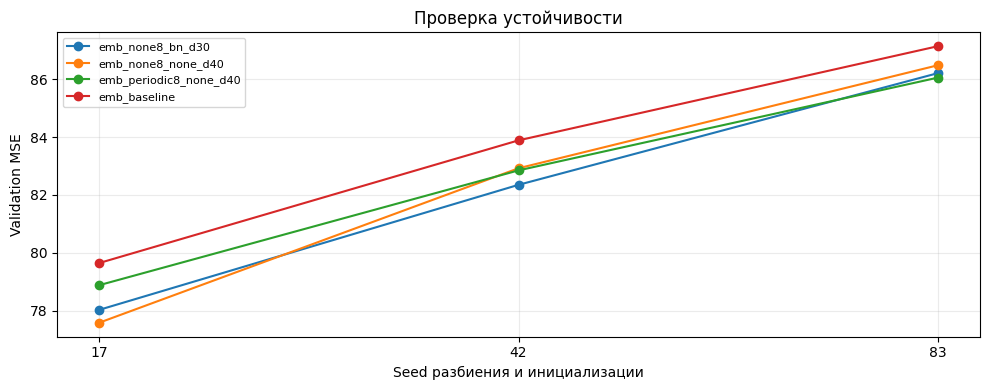

In [12]:
# Сравнение лидеров на трёх development-разбиениях (не audit).
fig, ax = plt.subplots(figsize=(10, 4))
for row in comparison:
    pairs = sorted((int(seed), value) for seed, value in row["mse_by_seed"].items())
    ax.plot([str(seed) for seed, _ in pairs], [value for _, value in pairs], marker="o", label=row["id"])
ax.set(xlabel="Seed разбиения и инициализации", ylabel="Validation MSE", title="Проверка устойчивости")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
